In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon as PatchPolygon
import numpy as np
from shapely.geometry import Polygon
from glob import glob
import pandas as pd

In [2]:
models = [
    "yolov8n-obb", "yolov8s-obb", "yolov8m-obb",
    "yolo11n-obb", "yolo11s-obb", "yolo11m-obb"
]

pred_labels_base_dir = "/kaggle/input/rasoul-b-e-s-obb-yolo-inference-on-test/runs/obb"
test_images_dir = "/kaggle/input/rasoul-b-e-s-obb/dataset/images/test"
gt_labels_dir = "/kaggle/input/rasoul-b-e-s-obb/dataset/labels/test"
save_base_dir = "/kaggle/working/binaryobb_misdetection_plots"

all_misprediction_data = []

In [3]:
def load_yolo_labels(path, with_conf=False):
    labels = {}
    for label_file in glob(f"{path}/*.txt"):
        with open(label_file, "r") as f:
            lines = f.read().strip().split("\n")
            boxes = []
            for line in lines:
                if not line.strip():
                    continue
                parts = list(map(float, line.strip().split()))
                if with_conf and len(parts) == 10:
                    conf = parts[-1]
                    box = parts[1:9]
                    boxes.append((conf, box))
                elif not with_conf and len(parts) == 9:
                    box = parts[1:9]
                    boxes.append(box)
                else:
                    print(f"⚠️ Skipping malformed line: {line} in {label_file}")
            labels[os.path.basename(label_file)] = boxes
    return labels

In [4]:
def normalize_to_sorted_polygon(box, image_shape=(640, 640)):
    pts = np.array([(box[i]*image_shape[1], box[i+1]*image_shape[0]) for i in range(0, 8, 2)], dtype=np.float32)
    rect = cv2.minAreaRect(pts)
    box_pts = cv2.boxPoints(rect)
    return Polygon(box_pts)

In [5]:
def compute_iou(box1, box2, image_shape=(640, 640)):
    poly1 = normalize_to_sorted_polygon(box1, image_shape)
    poly2 = normalize_to_sorted_polygon(box2, image_shape)
    if not poly1.is_valid or not poly2.is_valid:
        return 0.0
    inter = poly1.intersection(poly2).area
    union = poly1.union(poly2).area
    return inter / union if union > 0 else 0.0

In [6]:
def draw_obb(ax, polygon_coords, edge_color, label_text=None, image_shape=None, fontsize=8):
    poly_array = np.array(polygon_coords).reshape(4, 2)

    polygon = PatchPolygon(poly_array, closed=True, edgecolor=edge_color, facecolor='none', linewidth=1.5)
    ax.add_patch(polygon)

    if label_text:
        centroid_x = np.mean(poly_array[:, 0])
        centroid_y = np.mean(poly_array[:, 1])
        ax.text(
            centroid_x + 5, centroid_y - 5,
            label_text,
            fontsize=fontsize,
            color=edge_color,
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.3')
        )
        return centroid_x + 5, centroid_y - 5  # return text position

    return None  # no label, nothing to return

In [7]:
def visualize_misdetections(model_name,
                             test_images_dir,
                             gt_labels_dir,
                             pred_labels_base_dir,
                             save_dir,
                             iou_threshold=0.5):

    pred_labels_dir = os.path.join(pred_labels_base_dir, f"yolo_validation_predictions_{model_name}_test", "labels")
    os.makedirs(save_dir, exist_ok=True)

    gt_labels = load_yolo_labels(gt_labels_dir, with_conf=False)
    pred_labels = load_yolo_labels(pred_labels_dir, with_conf=True)

    img_files = glob(f"{test_images_dir}/*.jpg") + glob(f"{test_images_dir}/*.png")

    for img_path in img_files:
        img_name = os.path.basename(img_path)
        label_name = img_name.replace(".jpg", ".txt").replace(".png", ".txt")

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        gt_boxes = gt_labels.get(label_name, [])
        pred_info = pred_labels.get(label_name, [])

        preds = [b[1] for b in pred_info]
        confs = [b[0] for b in pred_info]

        false_positives = []
        false_negatives = []

        no_predictions = len(preds) == 0

        # FP: prediction has IoU < threshold with all GTs
        for i, pred_box in enumerate(preds):
            max_iou = max([compute_iou(pred_box, gt_box, (h, w)) for gt_box in gt_boxes], default=0)
            if max_iou < iou_threshold:
                false_positives.append((pred_box, confs[i], max_iou))
                all_misprediction_data.append([model_name, img_name, "FP", confs[i], max_iou])

        # FN: GT box has IoU < threshold with all predictions
        for gt_box in gt_boxes:
            max_iou = max([compute_iou(gt_box, pred_box, (h, w)) for pred_box in preds], default=0)
            if max_iou < iou_threshold:
                false_negatives.append((gt_box, 0.0))
                all_misprediction_data.append([model_name, img_name, "FN", None, 0.0])

        if false_positives or false_negatives or len(preds) > 0:
            fig, ax = plt.subplots(1, figsize=(10, 10))
            ax.imshow(img)
            ax.set_title(img_name, fontsize=10)

            if no_predictions:
                ax.add_patch(patches.Rectangle((0, 0), w, h, linewidth=8, edgecolor='red', facecolor='none'))
                ax.text(w // 2, 20, "No Predictions Made", fontsize=14, color='red',
                        ha='center', va='top', backgroundcolor='white', fontweight='bold')
                all_misprediction_data.append([model_name, img_name, "NoPred", None, None])

            # --- Smart label offset ---
            placed_text_coords = []

            def get_nonoverlapping_text_position(x_min, y_min, offset_step=12):
                new_y = y_min - 10
                for _ in range(10):
                    overlap = any(abs(x_min - x) < 30 and abs(new_y - y) < 15 for x, y in placed_text_coords)
                    if not overlap:
                        placed_text_coords.append((x_min, new_y))
                        return new_y
                    new_y -= offset_step
                placed_text_coords.append((x_min, new_y))
                return new_y

            # GT boxes in green
            for gt_box in gt_boxes:
                draw_obb(ax, gt_box, 'g', 'GT', (h, w), 3)

            # FP boxes in red
            fp_boxes_set = {tuple(map(lambda x: round(x, 5), box)) for box, _, _ in false_positives}
            for fp_box, conf, iou in false_positives:
                start = draw_obb(ax, fp_box, 'r', 'FP', (h, w))
                text_y = get_nonoverlapping_text_position(start[0], start[1])
                ax.text(start[0], text_y, f"Conf: {conf:.2f}\nIoU: {iou:.2f}",
                        color='r', fontsize=7, backgroundcolor='white')

            # FN boxes in blue
            for fn_box, _ in false_negatives:
                start = draw_obb(ax, fn_box, 'b', 'FN', (h, w))
                text_y = get_nonoverlapping_text_position(start[0], start[1])
                ax.text(start[0], text_y, f"IoU: 0.00", color='b', fontsize=7, backgroundcolor='white')

            # Draw all predicted boxes (orange), excluding already drawn FPs
            for i, pred_box in enumerate(preds):
                rounded_box = tuple(map(lambda x: round(x, 5), pred_box))
                if rounded_box in fp_boxes_set:
                    continue  # already plotted as FP
                start = draw_obb(ax, pred_box, 'orange', 'Pred', (h, w))
                text_y = get_nonoverlapping_text_position(start[0], start[1])
                ax.text(start[0], text_y, f"Conf: {confs[i]:.2f}", color='orange', fontsize=7, backgroundcolor='white')

            # Legend cleanup
            handles, labels = ax.get_legend_handles_labels()
            by_label = dict(zip(labels, handles))
            ax.legend(by_label.values(), by_label.keys())
            plt.axis("off")
            plt.savefig(os.path.join(save_dir, img_name), bbox_inches='tight', pad_inches=0.1)
            plt.close()

In [8]:
# Run for each model
for model in models:
    print(f"🔍 Visualizing misdetections for model: {model}")
    save_dir = os.path.join(save_base_dir, model)

    visualize_misdetections(
        model_name=model,
        test_images_dir=test_images_dir,
        gt_labels_dir=gt_labels_dir,
        pred_labels_base_dir=pred_labels_base_dir,
        save_dir=save_dir,
        iou_threshold=0.5
    )
    print(f"Misdetections of {model} saved to: {save_dir}")
    
    # Count number of images saved for this model
    saved_images = glob(os.path.join(save_base_dir, model, "*.png"))
    print(f"📸 Total misdetection images saved for {model}: {len(saved_images)}")

🔍 Visualizing misdetections for model: yolov8n-obb
Misdetections of yolov8n-obb saved to: /kaggle/working/binaryobb_misdetection_plots/yolov8n-obb
📸 Total misdetection images saved for yolov8n-obb: 154
🔍 Visualizing misdetections for model: yolov8s-obb
Misdetections of yolov8s-obb saved to: /kaggle/working/binaryobb_misdetection_plots/yolov8s-obb
📸 Total misdetection images saved for yolov8s-obb: 154
🔍 Visualizing misdetections for model: yolov8m-obb
Misdetections of yolov8m-obb saved to: /kaggle/working/binaryobb_misdetection_plots/yolov8m-obb
📸 Total misdetection images saved for yolov8m-obb: 154
🔍 Visualizing misdetections for model: yolo11n-obb
Misdetections of yolo11n-obb saved to: /kaggle/working/binaryobb_misdetection_plots/yolo11n-obb
📸 Total misdetection images saved for yolo11n-obb: 154
🔍 Visualizing misdetections for model: yolo11s-obb
Misdetections of yolo11s-obb saved to: /kaggle/working/binaryobb_misdetection_plots/yolo11s-obb
📸 Total misdetection images saved for yolo11s

✅ Misdetection summary saved to /kaggle/working/binary_misdetection_log.csv
📊 Bar plot saved to: /kaggle/working/binary_misdetection_barplot.png


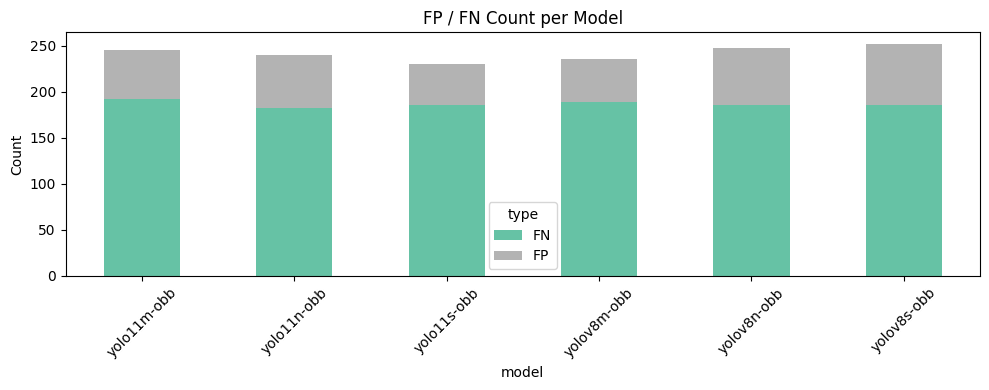

In [9]:
# Save CSV log of all misdetections, including "NoPred"
csv_log_path = "/kaggle/working/binary_misdetection_log.csv"
df = pd.DataFrame(all_misprediction_data, columns=["model", "image", "type", "confidence", "iou"])
df.to_csv(csv_log_path, index=False)
print(f"✅ Misdetection summary saved to {csv_log_path}")

# Exclude "NoPred" for plotting and summary
plot_df = df[df["type"] != "NoPred"]
summary = plot_df.groupby(["model", "type"]).size().unstack(fill_value=0)

# Save filtered summary CSV
summary.to_csv("/kaggle/working/binary_misdetection_summary_counts.csv")

# Plot FP/FN counts (excluding NoPred)
summary.plot(kind="bar", stacked=True, colormap="Set2", figsize=(10, 4))
plt.title("FP / FN Count per Model")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("/kaggle/working/binary_misdetection_barplot.png")
print("📊 Bar plot saved to: /kaggle/working/binary_misdetection_barplot.png")

In [10]:
!zip -r "/kaggle/working/binaryobb_misdetection_plots.zip" "/kaggle/working/binaryobb_misdetection_plots"

  adding: kaggle/working/binaryobb_misdetection_plots/ (stored 0%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/ (stored 0%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/MORAD MASOMEH-638573288796985478_11.png (deflated 4%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/PAJOYAN MARYAM-638573303529442642_18.png (deflated 4%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/RANJBAR FATEME-638573376220046811_4.png (deflated 5%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/RAMEZANNEJAD KEYHAN-638573350241112460_26.png (deflated 6%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/SALAQMI ALI ASGHAR-638573391302049659_24.png (deflated 6%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/SALAQMI ALI ASGHAR-638573391302049659_16.png (deflated 4%)
  adding: kaggle/working/binaryobb_misdetection_plots/yolo11m-obb/KAVAKTOO NASER-638573272666606514_15.png (deflated 